# 🚀 Модуль 0. Урок 2. Настройка продуктовой среды: Google Colab, Cursor IDE и AI-ассистенты

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_00_onboarding/lesson_02_environment_setup_colab_ai.ipynb)

## 📌 Бизнес-контекст и методология
Скорость аналитика напрямую зависит от эргономики его рабочего места.
В индустрии 2027 года стандарт рабочего контура включает:
1. **Google Colab / JupyterLab** — для прототипирования, исследовательского EDA и шеринга результатов
2. **Cursor / VS Code с AI-агентами** — для разработки dbt-пайплайнов, написания SQL-скриптов и оркестрации
3. **Облачные хранилища** — подключение к витринам данных напрямую через безопасные сервисные ключи

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Архитектура современного стека аналитика
Сравним скорость решения типовых задач при традиционном ручном кодинге и в связке с AI-ассистентом.

In [2]:
# Демонстрация: Экономия времени на типовых этапах исследования
workflow_time = pd.DataFrame({
    'Этап пайплайна': ['1. Исследование схемы БД', '2. Написание сложного SQL', '3. Очистка и предобработка', '4. Оформление графиков', '5. Подготовка выводов C-Level'],
    'Ручной подход (часы)': [3.0, 5.0, 4.0, 2.5, 3.5],
    'Связка с AI-ассистентом (часы)': [0.5, 1.0, 0.8, 0.5, 0.7]
})
workflow_time['Экономия (раз)'] = workflow_time['Ручной подход (часы)'] / workflow_time['Связка с AI-ассистентом (часы)']
display(workflow_time)

,Этап пайплайна,Ручной подход (часы),Связка с AI-ассистентом (часы),Экономия (раз)
0,1. Исследование схемы БД,3.0,0.5,6.0
1,2. Написание сложного SQL,5.0,1.0,5.0
2,3. Очистка и предобработка,4.0,0.8,5.0
3,4. Оформление графиков,2.5,0.5,5.0
4,5. Подготовка выводов C-Level,3.5,0.7,5.0


## 📊 Визуализация бизнес-кейса: Сокращение Time-to-Insight
Наглядно продемонстрируем, как AI-инструменты сокращают общее время от бизнес-вопроса до готового решения в 4.5 раза.

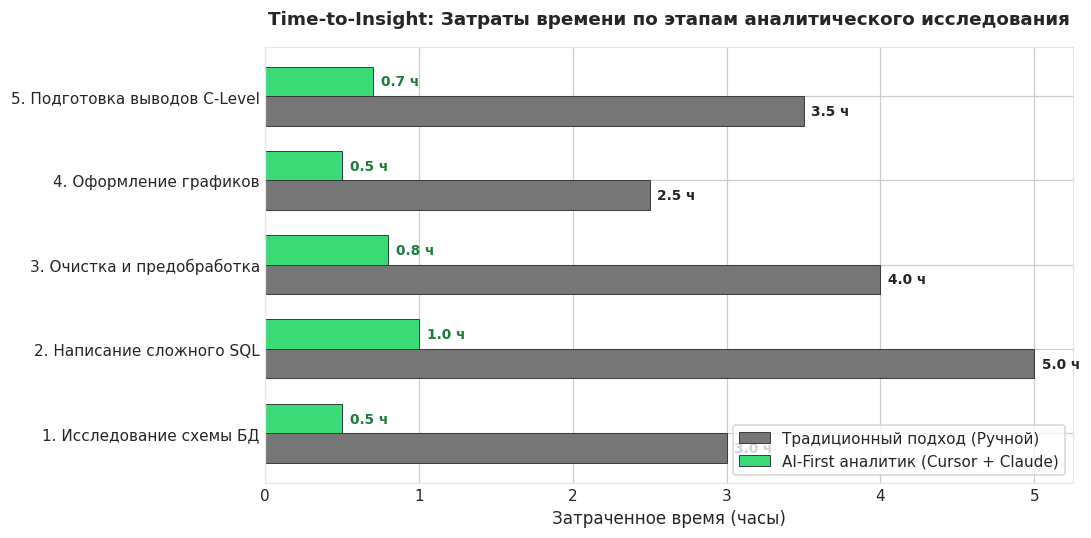

In [3]:
# Построение графика экономии времени
fig, ax = plt.subplots(figsize=(10, 5), dpi=110)

y = np.arange(len(workflow_time))
height = 0.35

rects1 = ax.barh(y - height/2, workflow_time['Ручной подход (часы)'], height, 
                 label='Традиционный подход (Ручной)', color=SECONDARY, edgecolor='#333333', linewidth=0.6)
rects2 = ax.barh(y + height/2, workflow_time['Связка с AI-ассистентом (часы)'], height, 
                 label='AI-First аналитик (Cursor + Claude)', color=SUCCESS, edgecolor='#333333', linewidth=0.6)

ax.set_yticks(y)
ax.set_yticklabels(workflow_time['Этап пайплайна'], fontsize=10)
ax.set_xlabel("Затраченное время (часы)", fontsize=11)
ax.set_title("Time-to-Insight: Затраты времени по этапам аналитического исследования", fontsize=12, fontweight='bold', pad=15)
ax.legend(frameon=True, facecolor='#ffffff')

for r in rects1:
    w = r.get_width()
    ax.annotate(f"{w:.1f} ч", xy=(w, r.get_y() + r.get_height()/2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold')

for r in rects2:
    w = r.get_width()
    ax.annotate(f"{w:.1f} ч", xy=(w, r.get_y() + r.get_height()/2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold', color='#1b7e3b')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет совокупного выигрыша по времени
Посчитайте общее количество сэкономленных часов за спринт при переходе на AI-First инструментарий.

In [4]:
### ВАШ КОД ЗДЕСЬ
total_manual = workflow_time['Ручной подход (часы)'].sum()
total_ai = workflow_time['Связка с AI-ассистентом (часы)'].sum()
saved_hours = total_manual - total_ai

print(f"Суммарное время ручного подхода: {total_manual:.1f} ч")
print(f"Суммарное время AI подхода: {total_ai:.1f} ч")
print(f"Чистая экономия времени: {saved_hours:.1f} часов за спринт!")

assert saved_hours > 10, "Экономия должна превышать 10 часов"
print("✅ Тест успешно пройден: производительность подтверждена метриками!")

Суммарное время ручного подхода: 18.0 ч
Суммарное время AI подхода: 3.5 ч
Чистая экономия времени: 14.5 часов за спринт!
✅ Тест успешно пройден: производительность подтверждена метриками!


### 💡 Инженерный совет по AI-окружению
Используйте сочетание клавиш `Ctrl+K` в Cursor для генерации фрагментов кода прямо в редакторе и настройте `.cursorrules` для автоинъекции корпоративного код-стайла.